# Fixed 50% depth spatial averaging QC

Statistics are computed within subject first, then summarized across subjects. The notebook combines the original pilot with the five additional subjects.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
result_root=Path('/mnt/newStor/paros/paros_WORK/xintong/results/native_surface_analysis')
files=[result_root/'spatial_averaging_pilot/tables/metrics_summary.csv']
files.extend(sorted((result_root/'spatial_averaging_five_subjects/shards').glob('D*/tables/metrics_summary.csv')))
files.extend(sorted((result_root/'spatial_averaging_k64_k128/shards').glob('D*/tables/metrics_summary.csv')))
frames=[pd.read_csv(path) for path in files if path.exists()]
metrics=pd.concat(frames,ignore_index=True).drop_duplicates(subset=['subject','hemisphere','region','method','k','repeat'])
metrics=metrics[metrics.status.eq('valid')].copy()
metrics['method_label']=metrics.method.map({'region':'Whole-region','spatial':'Spatial grouping','random':'Random grouping'})
print(f'Subjects: {metrics.subject.nunique()}; regions: {metrics.region.nunique()}')

Subjects: 9; regions: 4


## Subject-level metrics

In [ ]:
keys=['subject','hemisphere','region','method','k']
subject_metrics=metrics.groupby(keys,as_index=False).agg(mae=('mae','median'),rmse=('rmse','median'))
base=subject_metrics[subject_metrics.method.eq('region')&subject_metrics.k.eq(1)].rename(columns={'mae':'region_mae','rmse':'region_rmse'})[['subject','hemisphere','region','region_mae','region_rmse']]
subject_metrics=subject_metrics.merge(base,on=['subject','hemisphere','region'],how='left')
subject_metrics['mae_improvement_pct']=100*(subject_metrics.region_mae-subject_metrics.mae)/subject_metrics.region_mae
subject_metrics['rmse_improvement_pct']=100*(subject_metrics.region_rmse-subject_metrics.rmse)/subject_metrics.region_rmse
display(subject_metrics.head())

,subject,hemisphere,region,method,k,mae,rmse,region_mae,region_rmse,mae_improvement_pct,rmse_improvement_pct
0,D0007,lh,precentral,random,1,0.000199,0.000248,0.000199,0.000248,0.000000,0.000000
1,D0007,lh,precentral,random,2,0.000199,0.000248,0.000199,0.000248,-0.011350,-0.014595
2,D0007,lh,precentral,random,4,0.000199,0.000248,0.000199,0.000248,-0.025099,-0.033643
3,D0007,lh,precentral,random,8,0.000199,0.000248,0.000199,0.000248,-0.057611,-0.060702
4,D0007,lh,precentral,random,16,0.000199,0.000248,0.000199,0.000248,-0.104654,-0.128818


## Across-subject median and interquartile range

In [ ]:
summary=subject_metrics.groupby(['region','method','k'],as_index=False).agg(n_subjects=('subject','nunique'),mae_median=('mae','median'),mae_q25=('mae',lambda x:x.quantile(.25)),mae_q75=('mae',lambda x:x.quantile(.75)),rmse_median=('rmse','median'),rmse_q25=('rmse',lambda x:x.quantile(.25)),rmse_q75=('rmse',lambda x:x.quantile(.75)),improvement_median=('mae_improvement_pct','median'),improvement_q25=('mae_improvement_pct',lambda x:x.quantile(.25)),improvement_q75=('mae_improvement_pct',lambda x:x.quantile(.75)),subjects_improved=('mae_improvement_pct',lambda x:int((x>0).sum())))
summary['improved_subject_pct']=100*summary.subjects_improved/summary.n_subjects
display(summary.round(4))

,region,method,k,n_subjects,mae_median,mae_q25,mae_q75,rmse_median,rmse_q25,rmse_q75,improvement_median,improvement_q25,improvement_q75,subjects_improved,improved_subject_pct
0,precentral,random,1,9,0.0001,0.0001,0.0002,0.0002,0.0002,0.0002,0.0000,0.0000,0.0000,0,0.0000
1,precentral,random,2,9,0.0001,0.0001,0.0002,0.0002,0.0002,0.0002,-0.0078,-0.0123,-0.0057,0,0.0000
2,precentral,random,4,9,0.0001,0.0001,0.0002,0.0002,0.0002,0.0002,-0.0265,-0.0314,-0.0205,0,0.0000
3,precentral,random,8,9,0.0001,0.0001,0.0002,0.0002,0.0002,0.0002,-0.0548,-0.0621,-0.0489,0,0.0000
4,precentral,random,16,9,0.0001,0.0001,0.0002,0.0002,0.0002,0.0002,-0.1264,-0.1380,-0.1070,0,0.0000
5,precentral,random,32,9,0.0001,0.0001,0.0002,0.0002,0.0002,0.0002,-0.2547,-0.2668,-0.2273,0,0.0000
6,precentral,region,1,9,0.0001,0.0001,0.0002,0.0002,0.0002,0.0002,0.0000,0.0000,0.0000,0,0.0000
7,precentral,spatial,1,9,0.0001,0.0001,0.0002,0.0002,0.0002,0.0002,0.0000,0.0000,0.0000,0,0.0000
8,precentral,spatial,2,9,0.0001,0.0001,0.0002,0.0002,0.0002,0.0002,0.0514,-0.0986,0.8165,10,111.1111
9,precentral,spatial,4,9,0.0001,0.0001,0.0001,0.0002,0.0002,0.0002,2.8696,1.7586,4.4334,17,188.8889


## Region-specific MAE curves through K=32

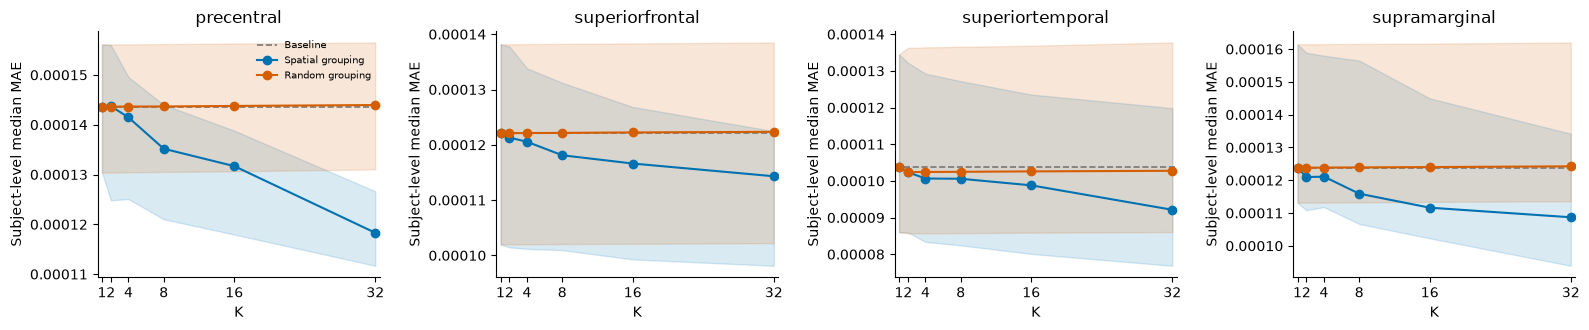

In [ ]:
plot_summary=summary[summary.k.le(32)].copy()
fig,axes=plt.subplots(1,plot_summary.region.nunique(),figsize=(4*plot_summary.region.nunique(),3.4),squeeze=False)
for ax,region in zip(axes.ravel(),sorted(plot_summary.region.unique())):
    part=plot_summary[plot_summary.region.eq(region)]
    baseline=part[part.method.eq('region')&part.k.eq(1)]
    if len(baseline):
        ax.axhline(baseline.mae_median.iloc[0],color='#777777',linestyle='--',linewidth=1.2,label='Baseline')
    for method,color,label in [('spatial','#0072B2','Spatial grouping'),('random','#D55E00','Random grouping')]:
        line=part[part.method.eq(method)].sort_values('k')
        if len(line):
            ax.plot(line.k,line.mae_median,marker='o',label=label,color=color)
            ax.fill_between(line.k,line.mae_q25,line.mae_q75,color=color,alpha=.15)
    ax.set_title(region)
    ax.set_xlabel('K')
    ax.set_ylabel('Subject-level median MAE')
    ax.set_xticks([1,2,4,8,16,32])
    ax.set_xlim(0.5,32.5)
    ax.spines[['top','right']].set_visible(False)
axes.ravel()[0].legend(frameon=False,fontsize=7)
fig.tight_layout()
plt.show()

## Spatial grouping improvement

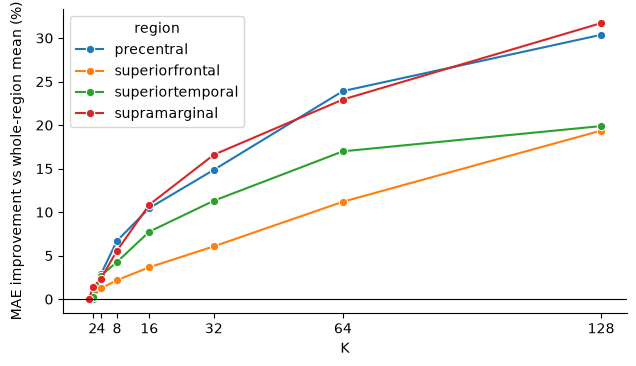

In [ ]:
spatial=summary[summary.method.eq('spatial')]
fig,ax=plt.subplots(figsize=(6.5,3.8))
sns.lineplot(data=spatial,x='k',y='improvement_median',hue='region',marker='o',ax=ax)
ax.axhline(0,color='black',linewidth=.8)
ax.set_xlabel('K')
ax.set_ylabel('MAE improvement vs whole-region mean (%)',labelpad=8)
ax.set_xticks([2,4,8,16,32,64,128])
ax.spines[['top','right']].set_visible(False)
fig.tight_layout(pad=1.2)
plt.show()

## Subject-level improvement curves

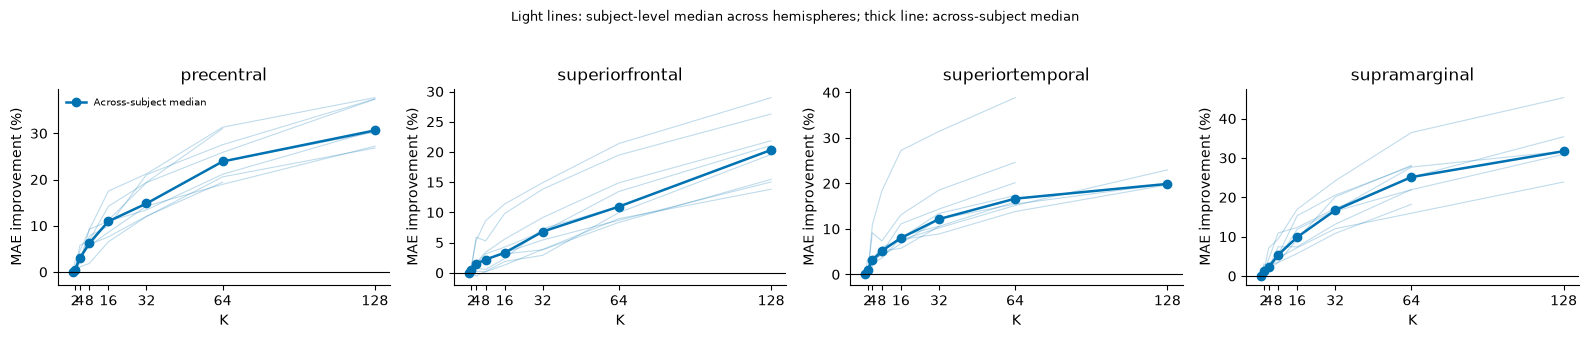

In [ ]:
spatial_subject=subject_metrics[subject_metrics.method.eq('spatial')].copy()
subject_curve=spatial_subject.groupby(['subject','region','k'],as_index=False).agg(mae_improvement_pct=('mae_improvement_pct','median'))
regions=sorted(subject_curve.region.unique())
fig,axes=plt.subplots(1,len(regions),figsize=(4*len(regions),3.4),squeeze=False)
for ax,region in zip(axes.ravel(),regions):
    part=subject_curve[subject_curve.region.eq(region)]
    for subject,group in part.groupby('subject'):
        group=group.sort_values('k')
        ax.plot(group.k,group.mae_improvement_pct,color='#0072B2',alpha=.25,linewidth=.8)
    median=part.groupby('k',as_index=False).mae_improvement_pct.median()
    ax.plot(median.k,median.mae_improvement_pct,color='#0072B2',marker='o',linewidth=1.8,label='Across-subject median')
    ax.axhline(0,color='black',linewidth=.8)
    ax.set_title(region)
    ax.set_xlabel('K')
    ax.set_ylabel('MAE improvement (%)')
    ax.set_xticks([2,4,8,16,32,64,128])
    ax.spines[['top','right']].set_visible(False)
axes.ravel()[0].legend(frameon=False,fontsize=7)
fig.suptitle('Light lines: subject-level median across hemispheres; thick line: across-subject median',fontsize=9)
fig.tight_layout(rect=[0,0,1,.94])
plt.show()

## Subject-level MAE curves through K=128

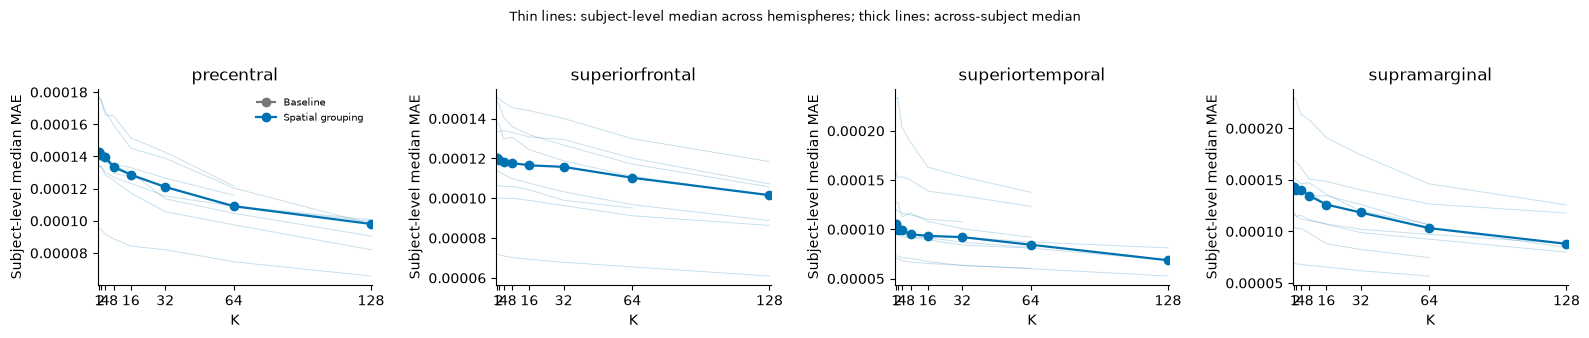

In [ ]:
mae_subject=subject_metrics.copy()
mae_subject=mae_subject[mae_subject.method.isin(['region','spatial'])].copy()
mae_subject=mae_subject.groupby(['subject','region','method','k'],as_index=False).agg(mae=('mae','median'))
mae_subject=mae_subject[mae_subject.k.le(128)]
regions=sorted(mae_subject.region.unique())
fig,axes=plt.subplots(1,len(regions),figsize=(4*len(regions),3.4),squeeze=False)
method_styles={'region':('#777777','--','Baseline'),'spatial':('#0072B2','-','Spatial grouping')}
for ax,region in zip(axes.ravel(),regions):
    part=mae_subject[mae_subject.region.eq(region)]
    for method,(color,linestyle,label) in method_styles.items():
        method_part=part[part.method.eq(method)]
        for subject,group in method_part.groupby('subject'):
            group=group.sort_values('k')
            ax.plot(group.k,group.mae,color=color,linestyle=linestyle,alpha=.22,linewidth=.7)
        median=method_part.groupby('k',as_index=False).mae.median()
        ax.plot(median.k,median.mae,color=color,linestyle=linestyle,marker='o',linewidth=1.6,label=label)
    ax.set_title(region)
    ax.set_xlabel('K')
    ax.set_ylabel('Subject-level median MAE')
    ax.set_xticks([1,2,4,8,16,32,64,128])
    ax.set_xlim(.5,128.5)
    ax.spines[['top','right']].set_visible(False)
axes.ravel()[0].legend(frameon=False,fontsize=7)
fig.suptitle('Thin lines: subject-level median across hemispheres; thick lines: across-subject median',fontsize=9)
fig.tight_layout(rect=[0,0,1,.94])
plt.show()